# Oja PCA

Oja's method updates the **leading principal direction directly**, without keeping a covariance matrix. With a controlled gain $\alpha_n$, the normalized update of the thesis proposal (eq. 2–3) is

$$\tilde q_{n+1}=q_n+\alpha_n\,(I-q_nq_n^\top)\,x_{n+1}x_{n+1}^\top q_n,\qquad q_{n+1}=\frac{\tilde q_{n+1}}{\lVert\tilde q_{n+1}\rVert}.$$

The covariance update with forgetting (eq. 1, `01_baselines`) and the Oja update are two implementations of the same idea: a gain $\alpha_n$ decides how much the newest observation moves the estimate. This notebook studies Oja with a **fixed** gain (later parts will also focus on a more adaptive approach).

### Organization

**Part 1: the method.** Same structure as `01_baselines`: one section with the four regimes and the same measurements and plots.

1. Oja PCA with a fixed gain

**Part 2: analysis.**

2. Comparable gains for Oja and forgetting PCA
3. Oja versus forgetting PCA at equal noise

**Summary**, **Sources**, and basic checks.

### Gains

The same $\alpha$ does not give the same memory in the two methods (Section 2): with the same number, Oja takes much bigger steps than forgetting PCA. Part 1 therefore uses $\alpha_{\text{Oja}}=\alpha/(\lambda_1-\lambda_2)$ for the gains $\alpha\in\{0.1,0.02,0.005\}$ of `01_baselines`, that is about $0.0222$, $0.00444$ and $0.00111$. Section 2 checks that each Oja gain has the same stationary noise as forgetting PCA with the corresponding $\alpha$, so the tables can be compared with `01_baselines` and with the windows $w\in\{19,99,399\}$ of `02_sliding_window`.


In [1]:
from pathlib import Path
import sys
import time

PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / 'methods.py').is_file() and (p / 'data_generators.py').is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Start Jupyter from online_pca_thesis or its notebooks folder.')
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import matplotlib.pyplot as plt

import plots as ut
from data_generators import generate_stationary, generate_abrupt, generate_smooth_rotation, generate_drift
from methods import oja_pca, forgetting_pca, tw_api_pca
from metrics import axis_error, axis_angle_error, trailing_mean, recovery_delay, recovery_delays
from benchmark import save_results, run_method, single_run, repeat_runs

In [2]:
# Same settings as 01_baselines
n_samples = 2000
lam1 = 5.0
lam2 = 0.5
theta0 = 0.0
theta1 = np.pi / 3
switch_step = 1000
omega = 0.001
q = 0.0001
dt = 1.0

seed = 0
seeds = range(20)
warmup = 200
smooth_window = 50
recovery_threshold = 0.05
recovery_hold = 50

spectral_gap = lam1 - lam2
gains = [0.005, 0.02, 0.1] # forgetting gains of 01_baselines, in the same order

def oja_gain_for(alpha):
    # Oja gain with the same stationary noise as forgetting PCA with gain alpha (Section 2)
    return alpha / spectral_gap

oja_gains = [oja_gain_for(alpha) for alpha in gains]
steps = np.arange(1, n_samples + 1)

assert lam1 > lam2 >= 0
assert 0 < warmup < switch_step < n_samples
print('Oja gains:', [f'{a:.5f}' for a in oja_gains])

Oja gains: ['0.00111', '0.00444', '0.02222']


## Data

The four regimes of `01_baselines`, with the same seeds.

In [3]:
def make_streams(generator, **kwargs):
    streams = {}
    for run_seed in seeds:
        X_run, theta_run, truth_run = generator(run_seed, n_samples=n_samples, lam1=lam1, lam2=lam2,
                                                theta0=theta0, **kwargs)
        for array in (X_run, theta_run, truth_run):
            array.setflags(write=False)
        streams[run_seed] = (X_run, theta_run, truth_run)
    return streams

streams = {
    'stationary': make_streams(generate_stationary),
    'abrupt': make_streams(generate_abrupt, theta1=theta1, switch_step=switch_step),
    'rotation': make_streams(generate_smooth_rotation, omega=omega, dt=dt),
    'drift': make_streams(generate_drift, Q=q, dt=dt),
}
scenarios = list(streams)
X_abrupt, theta_abrupt, truth_abrupt = streams['abrupt'][seed]

In [4]:
results_dir = PROJECT_ROOT / 'results' / 'oja'
results_dir.mkdir(parents=True, exist_ok=True)
base_settings = {
    'n_samples': n_samples, 'seeds': seeds, 'lam1': lam1, 'lam2': lam2,
    'theta0': theta0, 'theta1': theta1, 'switch_step': switch_step,
    'warmup': warmup, 'smooth_window': smooth_window,
    'recovery_threshold': recovery_threshold, 'recovery_hold': recovery_hold,
    'results_csv': results_dir / 'oja_results.csv',
}
rotation_settings = dict(base_settings, theta1='', switch_step='', recovery_threshold='', recovery_hold='',
                         results_csv=results_dir / f'oja_rotation_results_omega={omega:g}_dt={dt:g}.csv')
drift_settings = dict(base_settings, theta1='', switch_step='', recovery_threshold='', recovery_hold='',
                      results_csv=results_dir / f'oja_drift_results_Q={q:g}_dt={dt:g}.csv')
settings_for = {'stationary': base_settings, 'abrupt': base_settings,
                'rotation': rotation_settings, 'drift': drift_settings}

## Common tools

The measurements are the same as in `01_baselines` (raw and trailing-average axis error, cumulative error, signed angular error, captured variance, repeated-run mean with 10th–90th percentile band, recovery delay); see the section *How to read the measurement tables* there. The functions that produce them are in the project modules, next to the tools used by `01_baselines`: `benchmark.py` runs a method on the 20 streams of a regime (timing only the PCA calculation) and saves the CSV rows, and `plots.py` shows the tables and plots. Every setting is passed explicitly. The cell below only defines how the parameter values are labelled and the two dictionaries that collect the results of Part 1.

In [5]:
def gain_label(alpha):
    # Oja gain and the forgetting gain with the same stationary noise (Section 2)
    return f'Oja α={alpha:.5f} (≈ forgetting {alpha * spectral_gap:g})'

single = {}    # (method, scenario) -> {alpha: (directions, errors)} on the seed-0 stream
results = {}   # (method, scenario) -> {alpha: (runs, angles, runtimes)} on the 20 streams

# Part 1: the method

## 1. Oja PCA with a fixed gain

### Theory: a stochastic gradient step on the sphere

With $y=q_n^\top x_{n+1}$, the update is

$$\tilde q_{n+1}=q_n+\alpha_n\,y\,(x_{n+1}-y\,q_n),\qquad q_{n+1}=\tilde q_{n+1}/\lVert\tilde q_{n+1}\rVert .$$

- $x_{n+1}x_{n+1}^\top q_n=y\,x_{n+1}$ is a one-sample estimate of $\Sigma q_n$: the step is a stochastic version of one power iteration, or of a gradient step that increases $q^\top\Sigma q$ (Oja, 1982; Oja and Karhunen, 1985).
- The projection $(I-q_nq_n^\top)$ keeps only the part of the step perpendicular to $q_n$: it rotates $q$ without changing its length to first order. The normalization (eq. 3) removes the second-order change, so $q$ stays a unit vector. Since the added part is perpendicular to $q_n$, $\lVert\tilde q_{n+1}\rVert\ge1$ and the normalization is always defined.
- There is no covariance matrix and no eigendecomposition: one step costs a few products in any dimension.

`oja_pca(X, gain)` accepts a fixed gain or one gain per observation; it also returns the innovation $r_{n+1}=\lVert(I-q_nq_n^\top)x_{n+1}\rVert^2$ of eq. (4), computed with the direction available before $x_{n+1}$ is used. The estimate assumes a known zero population mean, as in `01_baselines`; the initial direction is the first axis.

### Stationary data

In [6]:
single['oja', 'stationary'] = single_run(oja_pca, oja_gains, streams['stationary'][seed])

#### Single-run measurements

In [7]:
ut.show_single_run(single['oja', 'stationary'], 'stationary', settings_for['stationary'], gain_label)

| Method | Mean error after warm-up | Temporal error SD |
| --- | --- | --- |
| Oja α=0.00111 (≈ forgetting 0.005) | 0.00042 | 0.00073 |
| Oja α=0.00444 (≈ forgetting 0.02) | 0.00142 | 0.00228 |
| Oja α=0.02222 (≈ forgetting 0.1) | 0.00734 | 0.01022 |


#### Repeat with 20 seeds

Use the shared stream stored for each seed. All sections use the same seed list. Rows in the saved array are runs, and columns are timesteps.

In [8]:
results['oja', 'stationary'] = repeat_runs(oja_pca, oja_gains, streams['stationary'], 'stationary', settings_for['stationary'],
                                   'Oja PCA', 'alpha')

Saved Oja PCA, stationary, alpha=0.0011111111111111111 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\oja\oja_results.csv


Saved Oja PCA, stationary, alpha=0.0044444444444444444 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\oja\oja_results.csv


Saved Oja PCA, stationary, alpha=0.022222222222222223 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\oja\oja_results.csv


#### Computational cost

In [9]:
ut.show_cost(results['oja', 'stationary'], gain_label)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| Oja α=0.00111 (≈ forgetting 0.005) | 0.012793085005250759 | 0.01079210004536435 | 0.013728899997659028 | 0.001013929048690749 |
| Oja α=0.00444 (≈ forgetting 0.02) | 0.013148385004024021 | 0.01101720001315698 | 0.015912099974229932 | 0.0011003373889146662 |
| Oja α=0.02222 (≈ forgetting 0.1) | 0.012896299993735738 | 0.010776499984785914 | 0.016956099949311465 | 0.0014171981939262042 |


#### Repeated-run plot

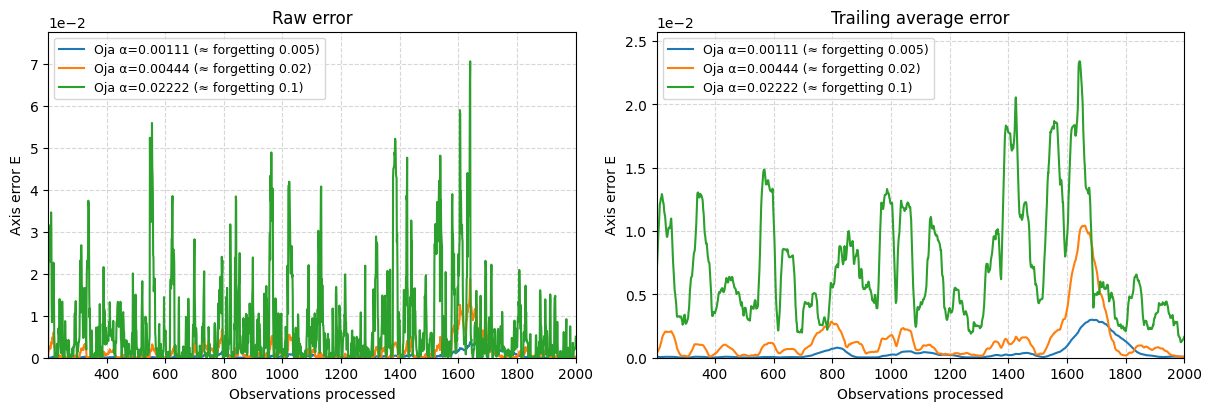

Oja α=0.00111 (≈ forgetting 0.005) cumulative error from observation 1: 0.7949196932618864
Oja α=0.00444 (≈ forgetting 0.02) cumulative error from observation 1: 2.716878744884671
Oja α=0.02222 (≈ forgetting 0.1) cumulative error from observation 1: 14.334417996779244


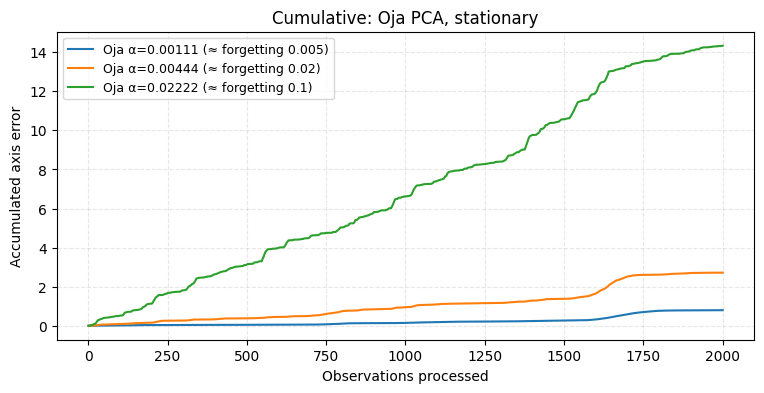

Oja α=0.00111 (≈ forgetting 0.005) stationary angle SD (degrees): 0.8551763397923813
Oja α=0.00444 (≈ forgetting 0.02) stationary angle SD (degrees): 1.9603734081064388
Oja α=0.02222 (≈ forgetting 0.1) stationary angle SD (degrees): 4.82164841765816


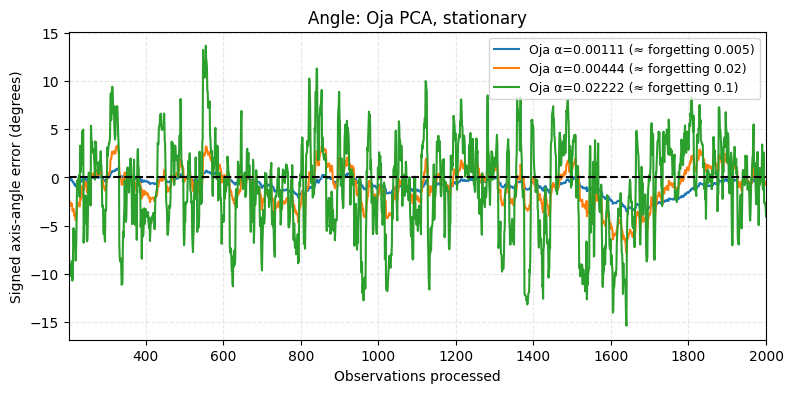

Oja α=0.00111 (≈ forgetting 0.005) mean captured variance after warm-up (%): 90.87447104942137
Oja α=0.00444 (≈ forgetting 0.02) mean captured variance after warm-up (%): 90.79262533608342
Oja α=0.02222 (≈ forgetting 0.1) mean captured variance after warm-up (%): 90.30893638482117


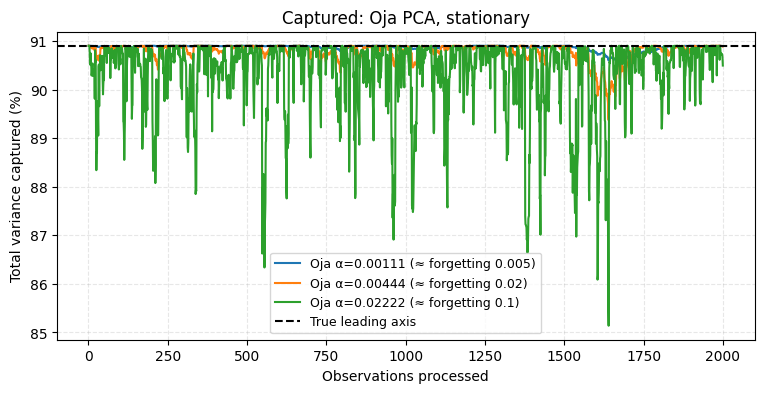

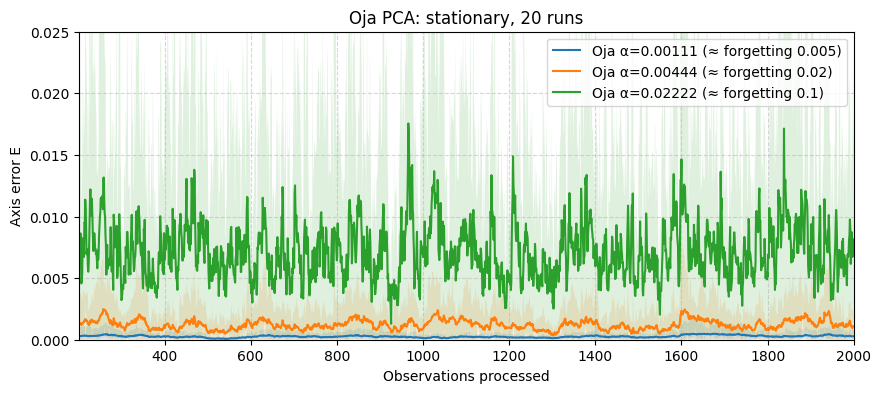

In [10]:
ut.show_plots(single['oja', 'stationary'], results['oja', 'stationary'], streams['stationary'][seed][1], 'stationary',
              settings_for['stationary'], 'Oja PCA', gain_label)

**Plots.**
- As for forgetting PCA, the noise grows with the gain. The largest gain reaches raw errors of about $0.07$ and angles of $\pm15^\circ$; the smallest moves slowly, between about $-5^\circ$ and $+1^\circ$.
- The bump around observation $1600$–$1700$ is in the data of this seed: it appears for every gain, as in `01_baselines`.
- With the smallest gain the cumulative error from observation $1$ is $0.79$, about half that of forgetting PCA with $\alpha=0.005$ ($1.54$). This comes from the start on the true axis (see the note in Section 3), not from a real advantage.
- The 20-run means are flat after warm-up, at three clearly separated levels.

#### Repeated-run measurements

In [11]:
ut.show_repeated_measurements(results['oja', 'stationary'], 'stationary', settings_for['stationary'], gain_label)

| Method | Mean E | SD of run means | Mean temporal SD |
| --- | --- | --- | --- |
| Oja α=0.00111 (≈ forgetting 0.005) | 0.00027 | 0.00012 | 0.00033 |
| Oja α=0.00444 (≈ forgetting 0.02) | 0.00123 | 0.00035 | 0.00167 |
| Oja α=0.02222 (≈ forgetting 0.1) | 0.00718 | 0.00079 | 0.01016 |


The stationary errors are those of forgetting PCA with the matched gains ($0.00027$, $0.00123$, $0.00718$ against $0.00030$, $0.00121$, $0.00680$): the scaled gains $\alpha/(\lambda_1-\lambda_2)$ give equal noise (Section 2). The largest gain is about $6\%$ above, close to the $5\%$ found in Section 2 at that gain; the smallest is slightly below, favoured by the starting point.

### Abrupt-change data

In [12]:
single['oja', 'abrupt'] = single_run(oja_pca, oja_gains, streams['abrupt'][seed])

#### Single-run measurements

In [13]:
ut.show_single_run(single['oja', 'abrupt'], 'abrupt', settings_for['abrupt'], gain_label)

| Method | Pre-change mean E | Post-change mean E | Final-segment mean E | Recovery delay |
| --- | --- | --- | --- | --- |
| Oja α=0.00111 (≈ forgetting 0.005) | 0.00014 | 0.14715 | 0.00135 | 474.0 |
| Oja α=0.00444 (≈ forgetting 0.02) | 0.00099 | 0.03500 | 0.00053 | 132.0 |
| Oja α=0.02222 (≈ forgetting 0.1) | 0.00686 | 0.01287 | 0.00348 | 57.0 |


#### Repeat with 20 seeds

In [14]:
results['oja', 'abrupt'] = repeat_runs(oja_pca, oja_gains, streams['abrupt'], 'abrupt', settings_for['abrupt'],
                                   'Oja PCA', 'alpha')

Saved Oja PCA, abrupt, alpha=0.0011111111111111111 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\oja\oja_results.csv


Saved Oja PCA, abrupt, alpha=0.0044444444444444444 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\oja\oja_results.csv


Saved Oja PCA, abrupt, alpha=0.022222222222222223 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\oja\oja_results.csv


#### Computational cost

In [15]:
ut.show_cost(results['oja', 'abrupt'], gain_label)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| Oja α=0.00111 (≈ forgetting 0.005) | 0.013416340001276695 | 0.01121419999981299 | 0.014456699951551855 | 0.001093516782180655 |
| Oja α=0.00444 (≈ forgetting 0.02) | 0.013852520004729741 | 0.012471899972297251 | 0.015854299999773502 | 0.000906443402266038 |
| Oja α=0.02222 (≈ forgetting 0.1) | 0.01432972498878371 | 0.012772499991115183 | 0.018325000011827797 | 0.0012769636881430802 |


#### Repeated-run plot

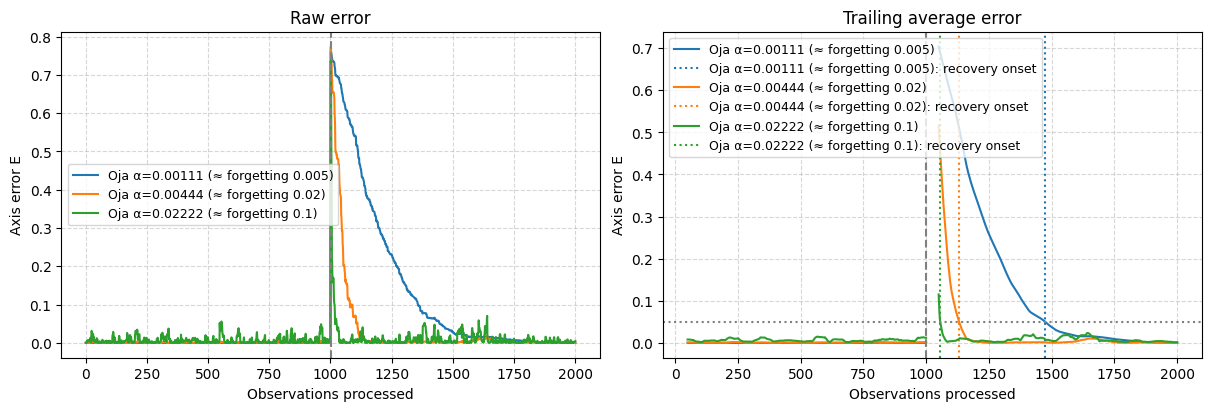

Oja α=0.00111 (≈ forgetting 0.005) cumulative error from observation 1: 147.29860147562107
Oja α=0.00444 (≈ forgetting 0.02) cumulative error from observation 1: 35.94712416927773
Oja α=0.02222 (≈ forgetting 0.1) cumulative error from observation 1: 19.495742804372064


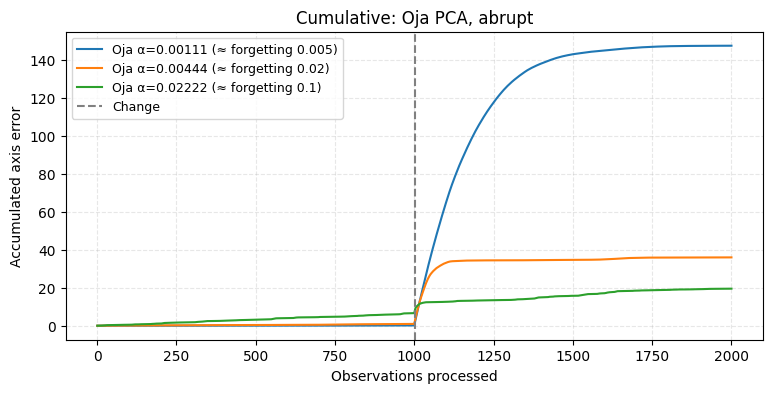

Oja α=0.00111 (≈ forgetting 0.005) stationary angle SD (degrees): 0.5693199531856907
Oja α=0.00444 (≈ forgetting 0.02) stationary angle SD (degrees): 1.6942062617795088
Oja α=0.02222 (≈ forgetting 0.1) stationary angle SD (degrees): 4.677026952436689


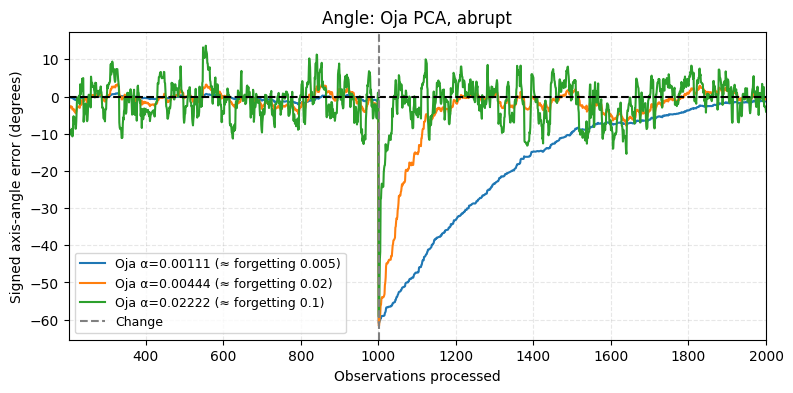

Oja α=0.00111 (≈ forgetting 0.005) mean captured variance after warm-up (%): 84.21521278658686
Oja α=0.00444 (≈ forgetting 0.02) mean captured variance after warm-up (%): 89.28215963497465
Oja α=0.02222 (≈ forgetting 0.1) mean captured variance after warm-up (%): 90.07433071174876


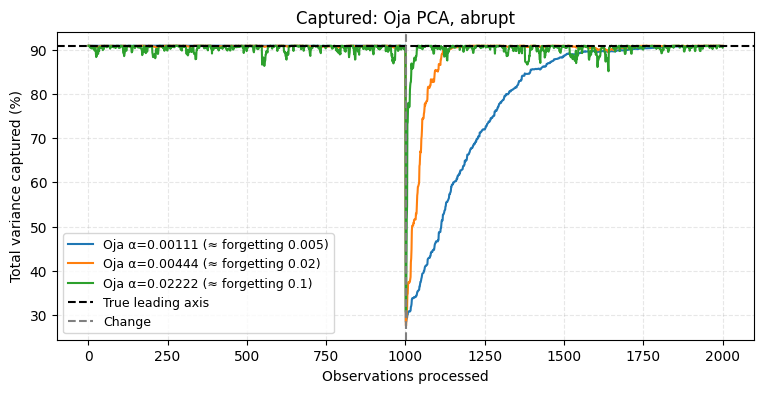

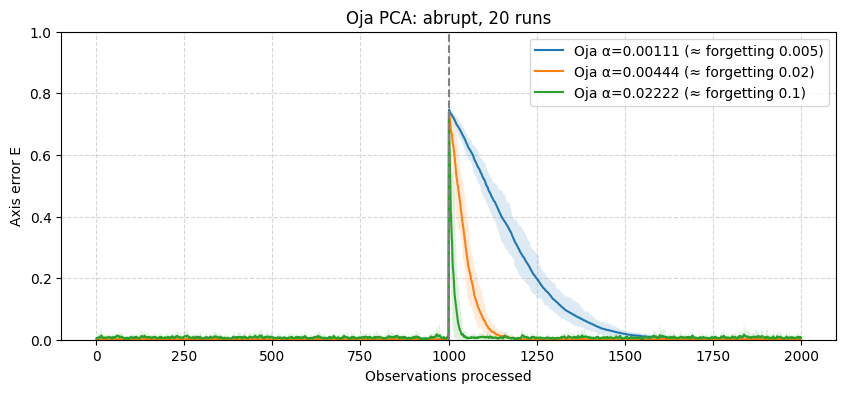

In [16]:
ut.show_plots(single['oja', 'abrupt'], results['oja', 'abrupt'], streams['abrupt'][seed][1], 'abrupt',
              settings_for['abrupt'], 'Oja PCA', gain_label)

**Plots.**
- Before the change the three gains behave as in stationary data.
- At the change the error jumps to $\sin^2 60^\circ=0.75$ and the angle to $-60^\circ$. The largest gain returns within about $50$ observations and the middle one within about $150$. The smallest needs about $500$, and its angle is still about $-2^\circ$ at the end of the stream.
- On this seed every gain is slower than forgetting PCA: recovery delays $474$, $132$, $57$ against $305$, $97$, $53$ (`01_baselines`).
- The 20-run bands are narrow: after the change the error is set by the gain, not by the noise.

#### Repeated-run measurements

Read the median recovery delay together with the recovered-run count: the median includes only runs that recovered.

In [17]:
ut.show_repeated_measurements(results['oja', 'abrupt'], 'abrupt', settings_for['abrupt'], gain_label)

| Method | Pre-change E: mean +/- SD | Post-change E: mean +/- SD | Final E: mean +/- SD | Recovered runs | Median delay |
| --- | --- | --- | --- | --- | --- |
| Oja α=0.00111 (≈ forgetting 0.005) | 0.00026 +/- 0.00011 | 0.13827 +/- 0.01618 | 0.00081 +/- 0.00074 | 20/20 | 423.0 |
| Oja α=0.00444 (≈ forgetting 0.02) | 0.00120 +/- 0.00039 | 0.03575 +/- 0.00737 | 0.00140 +/- 0.00116 | 20/20 | 130.0 |
| Oja α=0.02222 (≈ forgetting 0.1) | 0.00713 +/- 0.00116 | 0.01444 +/- 0.00424 | 0.00787 +/- 0.00278 | 20/20 | 58.5 |


- **Pre-change:** the stationary noise ($0.00026$, $0.00120$, $0.0071$), as expected.
- **Post-change:** the ranking inverts, as for forgetting PCA: the largest gain is the best ($0.0144$) and the smallest the worst ($0.138$). Every value is $30$–$55\%$ above forgetting PCA ($0.0894$, $0.0234$, $0.0110$), and the delays are longer ($423$, $130$, $58.5$ against $260.5$, $91.5$, $53.5$).
- **Final segment:** close to the stationary level for the two larger gains. For the smallest it is $0.00081$, three times its pre-change value, while forgetting PCA is back to it ($0.00035$ against $0.00034$): with that gain Oja has not finished the transient by the end of the stream.
- **Recovered and median delay:** all 20 runs recover, for every gain. Section 3 compares the recovery of the two methods.

### Smooth rotation data

In [18]:
single['oja', 'rotation'] = single_run(oja_pca, oja_gains, streams['rotation'][seed])

#### Single-run measurements

In [19]:
ut.show_single_run(single['oja', 'rotation'], 'rotation', settings_for['rotation'], gain_label)

| Method | Mean error after warm-up | Temporal error SD |
| --- | --- | --- |
| Oja α=0.00111 (≈ forgetting 0.005) | 0.04320 | 0.01161 |
| Oja α=0.00444 (≈ forgetting 0.02) | 0.00535 | 0.00507 |
| Oja α=0.02222 (≈ forgetting 0.1) | 0.00772 | 0.01099 |


#### Repeat with 20 seeds

Use the shared stream stored for each seed. All sections use the same seed list. Rows in the saved array are runs, and columns are timesteps.

In [20]:
results['oja', 'rotation'] = repeat_runs(oja_pca, oja_gains, streams['rotation'], 'rotation', settings_for['rotation'],
                                   'Oja PCA', 'alpha')

Saved Oja PCA, rotation, alpha=0.0011111111111111111 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\oja\oja_rotation_results_omega=0.001_dt=1.csv


Saved Oja PCA, rotation, alpha=0.0044444444444444444 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\oja\oja_rotation_results_omega=0.001_dt=1.csv


Saved Oja PCA, rotation, alpha=0.022222222222222223 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\oja\oja_rotation_results_omega=0.001_dt=1.csv


#### Computational cost

In [21]:
ut.show_cost(results['oja', 'rotation'], gain_label)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| Oja α=0.00111 (≈ forgetting 0.005) | 0.014102124999044462 | 0.013391799991950393 | 0.015029800008051097 | 0.00036497787935613473 |
| Oja α=0.00444 (≈ forgetting 0.02) | 0.014024385009543039 | 0.011919100012164563 | 0.017326800036244094 | 0.0011097131412021513 |
| Oja α=0.02222 (≈ forgetting 0.1) | 0.0138620599929709 | 0.012956399994436651 | 0.015056799980811775 | 0.0004437705917008974 |


#### Repeated-run plot

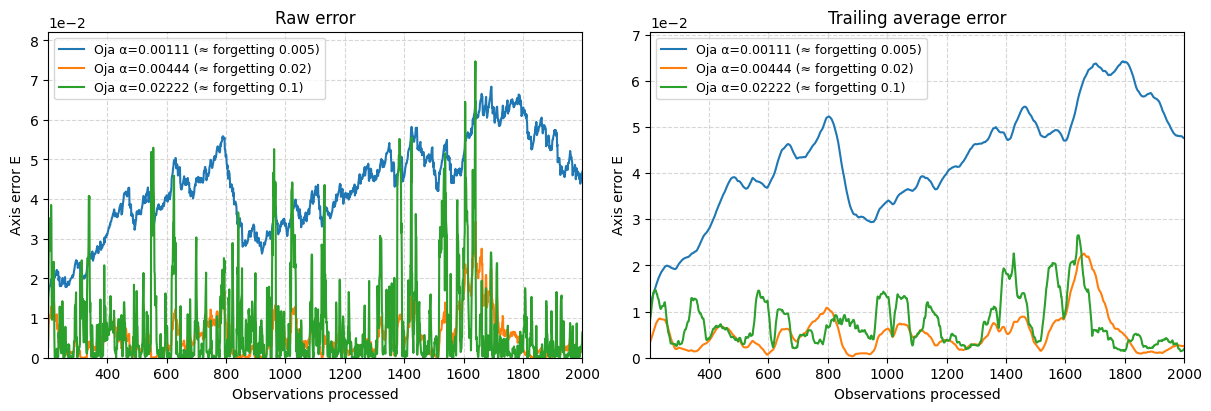

Oja α=0.00111 (≈ forgetting 0.005) cumulative error from observation 1: 78.75978159022438
Oja α=0.00444 (≈ forgetting 0.02) cumulative error from observation 1: 9.858050254566548
Oja α=0.02222 (≈ forgetting 0.1) cumulative error from observation 1: 15.106633955206506


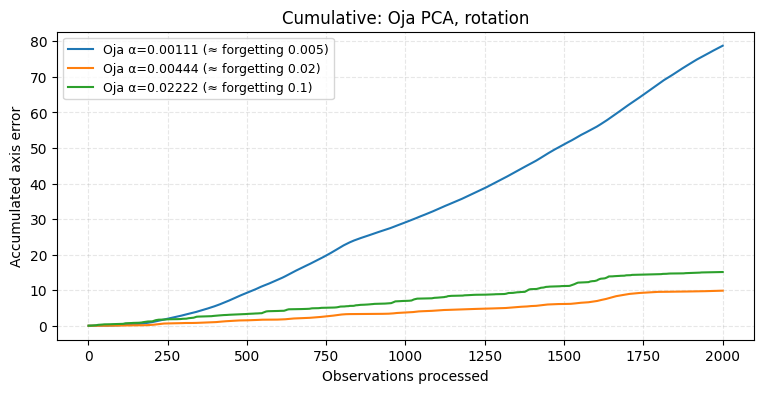

Oja α=0.00111 (≈ forgetting 0.005) tracking angle-error SD (degrees): 1.7003987743056133
Oja α=0.00444 (≈ forgetting 0.02) tracking angle-error SD (degrees): 1.9447405264686755
Oja α=0.02222 (≈ forgetting 0.1) tracking angle-error SD (degrees): 4.819727048125639


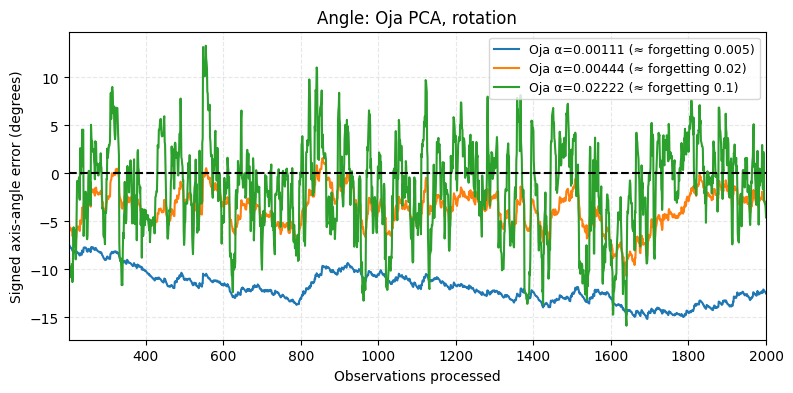

Oja α=0.00111 (≈ forgetting 0.005) mean captured variance after warm-up (%): 87.3742202727246
Oja α=0.00444 (≈ forgetting 0.02) mean captured variance after warm-up (%): 90.47167553316456
Oja α=0.02222 (≈ forgetting 0.1) mean captured variance after warm-up (%): 90.2771696257881


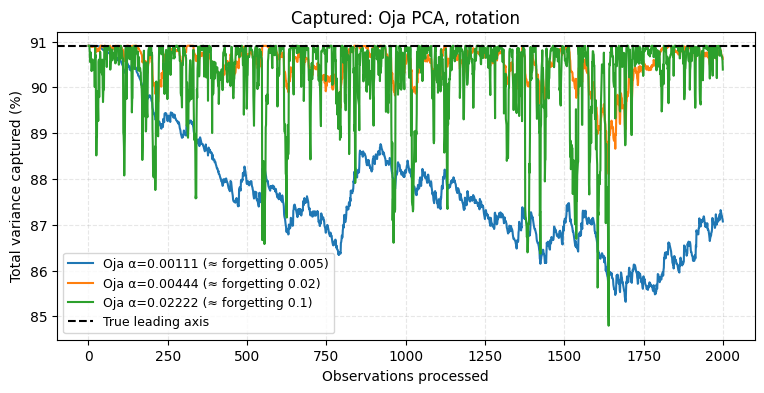

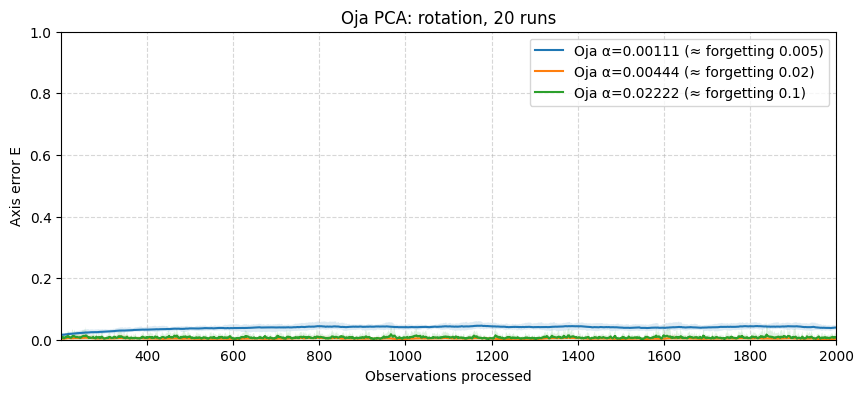

In [22]:
ut.show_plots(single['oja', 'rotation'], results['oja', 'rotation'], streams['rotation'][seed][1], 'rotation',
              settings_for['rotation'], 'Oja PCA', gain_label)

**Plots.**
- The smallest gain lags behind the rotation for the whole run: in this seed its angle goes from about $-8^\circ$ to $-15^\circ$, and its raw error stays around $0.03$–$0.06$. The middle gain lags by a few degrees with moderate noise; the largest is centred but noisy.
- The middle gain has the lowest cumulative error ($9.9$, against $78.8$ and $15.1$): with both lag and noise, the intermediate gain is best, as for forgetting PCA.
- In the 20-run plot the vertical limit ($1$) flattens the curves; the levels are those of the table below.

#### Repeated-run measurements

In [23]:
ut.show_repeated_measurements(results['oja', 'rotation'], 'rotation', settings_for['rotation'], gain_label)

| Method | Mean E | SD of run means | Mean temporal SD |
| --- | --- | --- | --- |
| Oja α=0.00111 (≈ forgetting 0.005) | 0.03909 | 0.00392 | 0.00925 |
| Oja α=0.00444 (≈ forgetting 0.02) | 0.00391 | 0.00103 | 0.00401 |
| Oja α=0.02222 (≈ forgetting 0.1) | 0.00731 | 0.00087 | 0.01033 |


Same ranking as forgetting PCA: the middle gain is the best ($0.00391$). At the two larger gains Oja and forgetting PCA are close ($0.00391$ against $0.00383$, $0.00731$ against $0.00693$). At the smallest gain Oja is about $25\%$ worse ($0.0391$ against $0.0314$); with a larger lag ($-11.3^\circ$ against $-10.1^\circ$, Section 3).

### Random drift data

In [24]:
single['oja', 'drift'] = single_run(oja_pca, oja_gains, streams['drift'][seed])

#### Single-run measurements

In [25]:
ut.show_single_run(single['oja', 'drift'], 'drift', settings_for['drift'], gain_label)

| Method | Mean error after warm-up | Temporal error SD |
| --- | --- | --- |
| Oja α=0.00111 (≈ forgetting 0.005) | 0.01333 | 0.01768 |
| Oja α=0.00444 (≈ forgetting 0.02) | 0.00512 | 0.00770 |
| Oja α=0.02222 (≈ forgetting 0.1) | 0.00836 | 0.01139 |


#### Repeat with 20 seeds

In [26]:
results['oja', 'drift'] = repeat_runs(oja_pca, oja_gains, streams['drift'], 'drift', settings_for['drift'],
                                   'Oja PCA', 'alpha')

Saved Oja PCA, drift, alpha=0.0011111111111111111 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\oja\oja_drift_results_Q=0.0001_dt=1.csv


Saved Oja PCA, drift, alpha=0.0044444444444444444 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\oja\oja_drift_results_Q=0.0001_dt=1.csv


Saved Oja PCA, drift, alpha=0.022222222222222223 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\oja\oja_drift_results_Q=0.0001_dt=1.csv


#### Computational cost

In [27]:
ut.show_cost(results['oja', 'drift'], gain_label)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| Oja α=0.00111 (≈ forgetting 0.005) | 0.01360920000297483 | 0.012410399969667196 | 0.01411230000667274 | 0.00035092152778053463 |
| Oja α=0.00444 (≈ forgetting 0.02) | 0.013488409988349303 | 0.011357699986547232 | 0.015399199968669564 | 0.0008343891773332749 |
| Oja α=0.02222 (≈ forgetting 0.1) | 0.013899320003110916 | 0.011459000001195818 | 0.022205099987331778 | 0.002081368045380044 |


#### Repeated-run plot

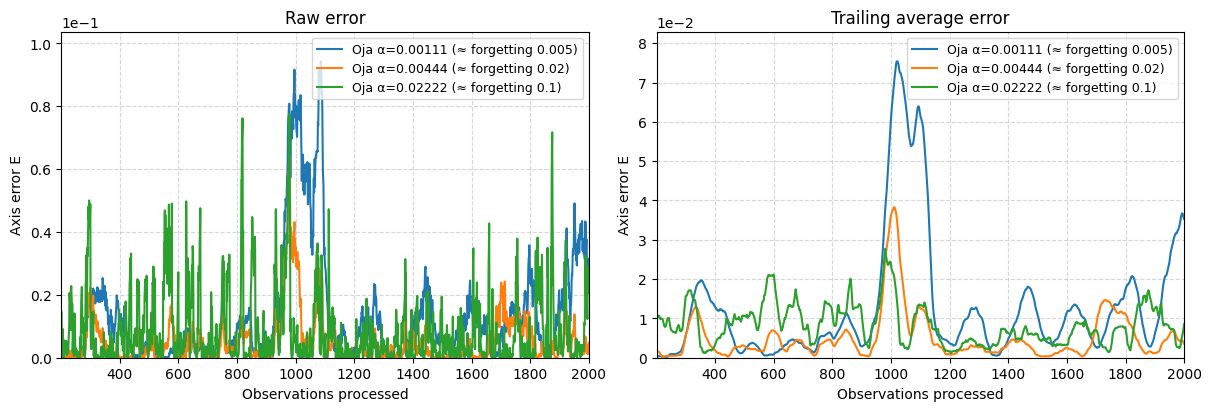

Oja α=0.00111 (≈ forgetting 0.005) cumulative error from observation 1: 24.389361153414114
Oja α=0.00444 (≈ forgetting 0.02) cumulative error from observation 1: 9.537118468597486
Oja α=0.02222 (≈ forgetting 0.1) cumulative error from observation 1: 16.563056693521336


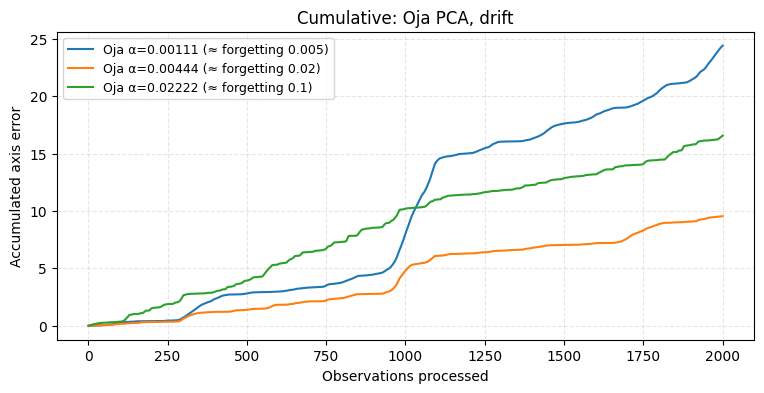

Oja α=0.00111 (≈ forgetting 0.005) tracking angle-error SD (degrees): 5.627013483828599
Oja α=0.00444 (≈ forgetting 0.02) tracking angle-error SD (degrees): 3.791154872909558
Oja α=0.02222 (≈ forgetting 0.1) tracking angle-error SD (degrees): 5.194857143779801


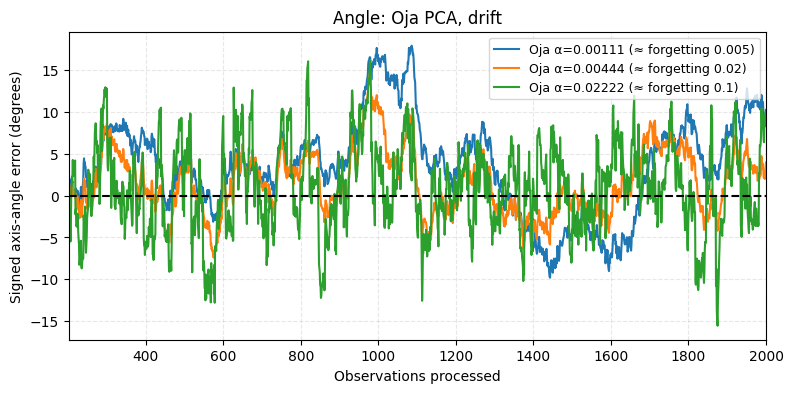

Oja α=0.00111 (≈ forgetting 0.005) mean captured variance after warm-up (%): 89.81861426092694
Oja α=0.00444 (≈ forgetting 0.02) mean captured variance after warm-up (%): 90.4903459156701
Oja α=0.02222 (≈ forgetting 0.1) mean captured variance after warm-up (%): 90.22517386889447


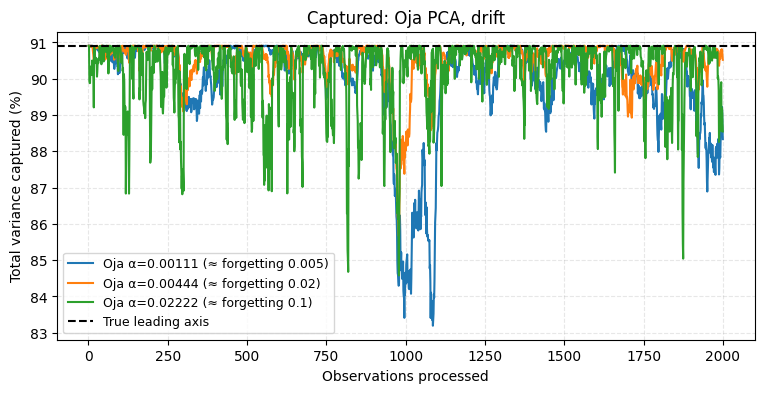

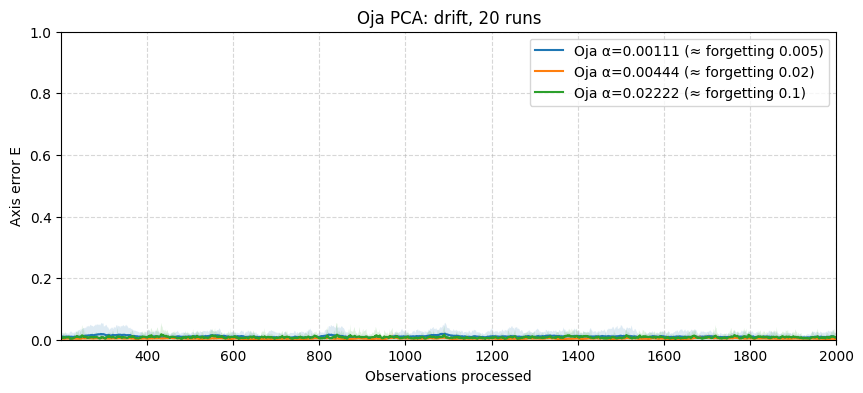

In [28]:
ut.show_plots(single['oja', 'drift'], results['oja', 'drift'], streams['drift'][seed][1], 'drift',
              settings_for['drift'], 'Oja PCA', gain_label)

**Plots.**
- The errors peak where the drift is fast, around observation $1000$–$1100$ in this seed, as in `01_baselines`. The smallest gain suffers most there; the largest is noisy everywhere.
- The middle gain has the lowest cumulative error ($9.5$, against $24.4$ and $16.6$).
- The angle has no systematic sign: the drift has no preferred direction.

#### Repeated-run measurements

In [29]:
ut.show_repeated_measurements(results['oja', 'drift'], 'drift', settings_for['drift'], gain_label)

| Method | Mean E | SD of run means | Mean temporal SD |
| --- | --- | --- | --- |
| Oja α=0.00111 (≈ forgetting 0.005) | 0.01036 | 0.00393 | 0.01301 |
| Oja α=0.00444 (≈ forgetting 0.02) | 0.00368 | 0.00063 | 0.00489 |
| Oja α=0.02222 (≈ forgetting 0.1) | 0.00782 | 0.00079 | 0.01092 |


The intermediate gain is the best ($0.00368$, against $0.0104$ and $0.00782$), as for forgetting PCA. At that gain the two methods are equal ($0.00368$ against $0.00366$); at the other two forgetting PCA is slightly better ($0.00926$ against $0.0104$, $0.00757$ against $0.00782$).

### Part 1 results

Mean axis error after warm-up over 20 seeds, at equal stationary noise (abrupt: error after the change, recovered runs and
median recovery delay). Benchmarks from `01_baselines` and `02_sliding_window`.

| Memory level | Method | Stationary | Abrupt, after the change | Rotation | Drift |
|---|---|---|---|---|---|
| $\alpha=0.005$ | Oja ($0.00111$) | 0.00027 | 0.138 (20/20, 423) | 0.0391 | 0.0104 |
| | forgetting | 0.00030 | 0.0894 (20/20, 260.5) | 0.0314 | 0.00926 |
| | window ($w=399$) | 0.00027 | 0.124 (20/20, 304) | 0.0381 | 0.0127 |
| $\alpha=0.02$ | Oja ($0.00444$) | 0.00123 | 0.0358 (20/20, 130) | 0.00391 | 0.00368 |
| | forgetting | 0.00121 | 0.0234 (20/20, 91.5) | 0.00383 | 0.00366 |
| | window ($w=99$) | 0.00123 | 0.0316 (20/20, 102) | 0.00381 | 0.00469 |
| $\alpha=0.1$ | Oja ($0.0222$) | 0.00718 | 0.0144 (20/20, 58.5) | 0.00731 | 0.00782 |
| | forgetting | 0.00680 | 0.0110 (20/20, 53.5) | 0.00693 | 0.00757 |
| | window ($w=19$) | 0.00733 | 0.0126 (20/20, 55) | 0.00744 | 0.00823 |

- **Near the true axis Oja behaves like forgetting PCA.** With $\alpha_{\text{Oja}}=\alpha/(\lambda_1-\lambda_2)$ the two
  methods have the same stationary noise ($0.00123$ against $0.00121$ for
  $\alpha=0.02$) and the same error under random
  drift ($0.00368$ against $0.00366$). Oja updates one direction with a few vector operations and never forms a
  covariance matrix, so it reaches the same accuracy with less memory and computation.
- **After a large change Oja is the slowest method.** Its post-change error is $30$–$55\%$ above forgetting PCA
  at every level, with longer delays ($130$ against $91.5$ steps for $\alpha=0.02$), and it is also behind the
  window.
- **The regimes rank the gains as for the other methods.** The smallest gain is best in stationary data, the
  largest after the abrupt change, and the intermediate one in rotation and drift, where noise and lag both
  matter. A fixed Oja gain therefore has the same trade-off as a fixed forgetting gain: no value is good for
  every regime (`04_sensitivity_analysis`, Part B).
- **The gain must be scaled with the data.** With the same numerical $\alpha$, Oja is $4.6$–$7.5$ times noisier than
  forgetting PCA (Section 2), because its step multiplies $xx^\top$ and therefore grows with the variance of the
  data. A controller choosing the gain for Oja has to account for the spectral gap; in the reduced model of the
  thesis proposal this issue will re-appear.
- Oja recovers for every single run.

# Part 2: analysis

# 2. Comparable gains for Oja and forgetting PCA

Part 1 does not give Oja the same gains as forgetting PCA, because the gain does not play the same role in the two updates.

- *Forgetting PCA*. Anderson (1963) gives the asymptotic error of the leading eigenvector estimated from $n$ observations, $\lambda_1\lambda_2/(n(\lambda_1-\lambda_2)^2)$. $\alpha$ is the weight of the newest observation in the covariance estimate: a number between $0$ and $1$, whatever the data.
- *Oja*. In Oja's update, $\alpha$ multiplies $x_{n+1}x_{n+1}^\top$, so the size of a step also depends on the variance of the data. Near the true axis, the mean dynamics of Oja's update approach the leading direction at a rate proportional to $\alpha(\lambda_1-\lambda_2)$ (Oja and Karhunen, 1985, Lemma 2): the spectral gap acts as a scale for the gain.

Part 1 therefore divides the forgetting gains by the gap, $\alpha_{\text{Oja}}=\alpha/(\lambda_1-\lambda_2)$, with $\lambda_1-\lambda_2=4.5$ here: the bound of Li et al. (2018, Theorem 1) on the stationary error of Oja's update has the same dependence on the gap, but an unspecified constant. On stationary data, Oja with $\alpha/(\lambda_1-\lambda_2)$ and forgetting PCA with $\alpha$ should have the same error.

The next cell measures the stationary error over a grid of gains $\alpha$ for forgetting PCA, for Oja with the scaled gain $\alpha/(\lambda_1-\lambda_2)$, and, for comparison, for Oja with the same numerical gain $\alpha$. It uses longer stationary streams ($4000$ observations, error averaged after observation $1000$), so that the start-up has no effect.

In [30]:
long_n, long_start = 4000, 1000
long_streams = []
for run_seed in seeds:
    X_run, _, truth_run = generate_stationary(run_seed, n_samples=long_n, lam1=lam1, lam2=lam2, theta0=theta0)
    long_streams.append((X_run, truth_run))

def stationary_error(fn):
    # mean axis error after observation long_start, averaged over the 20 long streams
    return np.mean([axis_error(fn(X_run), truth_run)[long_start:].mean() for X_run, truth_run in long_streams])

grid = [0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.4]
error_forgetting = [stationary_error(lambda X: forgetting_pca(X, a)[0]) for a in grid]
error_oja_scaled = [stationary_error(lambda X: oja_pca(X, oja_gain_for(a))[0]) for a in grid]
error_oja_same = [stationary_error(lambda X: oja_pca(X, a)[0]) for a in grid]

rows = []
for a, e_cov, e_scaled, e_same in zip(grid, error_forgetting, error_oja_scaled, error_oja_same):
    rows.append([a, f'{oja_gain_for(a):.5f}', f'{e_cov:.5f}', f'{e_scaled:.5f}', f'{e_scaled / e_cov:.2f}',
                 f'{e_same:.5f}', f'{e_same / e_cov:.1f}'])
ut.show_table(['Forgetting α', 'Oja α/(λ1-λ2)', 'E, forgetting', 'E, Oja with α/(λ1-λ2)', 'Ratio',
               'E, Oja with the same α', 'Ratio'], rows)

| Forgetting α | Oja α/(λ1-λ2) | E, forgetting | E, Oja with α/(λ1-λ2) | Ratio | E, Oja with the same α | Ratio |
| --- | --- | --- | --- | --- | --- | --- |
| 0.002 | 0.00044 | 0.00012 | 0.00012 | 0.97 | 0.00055 | 4.6 |
| 0.005 | 0.00111 | 0.00030 | 0.00030 | 1.01 | 0.00144 | 4.9 |
| 0.01 | 0.00222 | 0.00061 | 0.00062 | 1.02 | 0.00301 | 4.9 |
| 0.02 | 0.00444 | 0.00124 | 0.00128 | 1.03 | 0.00647 | 5.2 |
| 0.05 | 0.01111 | 0.00324 | 0.00337 | 1.04 | 0.01974 | 6.1 |
| 0.1 | 0.02222 | 0.00692 | 0.00730 | 1.05 | 0.05013 | 7.2 |
| 0.2 | 0.04444 | 0.01576 | 0.01694 | 1.07 | 0.11832 | 7.5 |
| 0.4 | 0.08889 | 0.04405 | 0.04285 | 0.97 | 0.22120 | 5.0 |


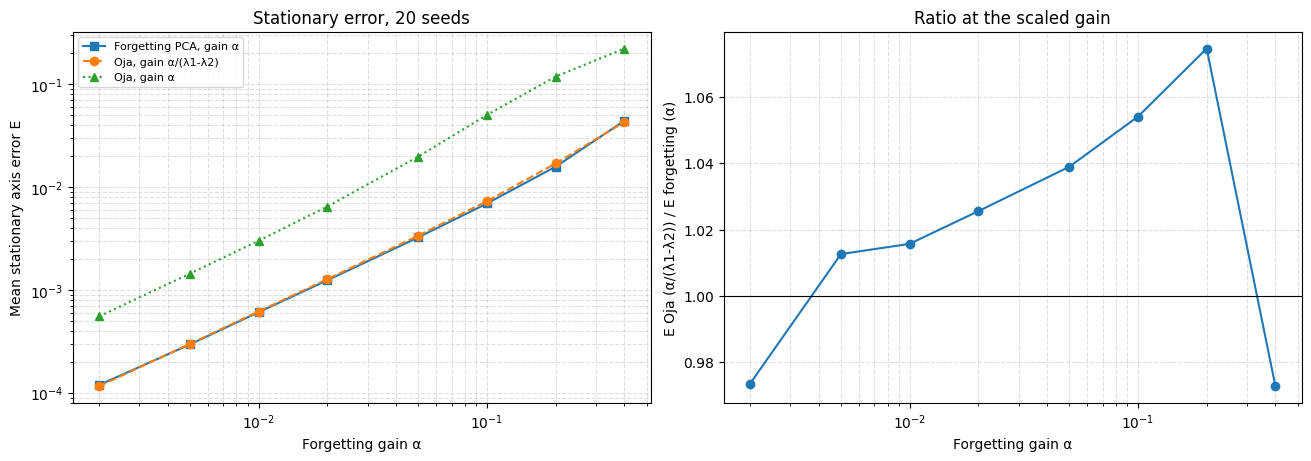

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
axes[0].loglog(grid, error_forgetting, 's-', label='Forgetting PCA, gain α')
axes[0].loglog(grid, error_oja_scaled, 'o--', label='Oja, gain α/(λ1-λ2)')
axes[0].loglog(grid, error_oja_same, '^:', label='Oja, gain α')
axes[0].set_xlabel('Forgetting gain α')
axes[0].set_ylabel('Mean stationary axis error E')
axes[0].set_title('Stationary error, 20 seeds')

axes[1].semilogx(grid, np.array(error_oja_scaled) / np.array(error_forgetting), 'o-')
axes[1].axhline(1, color='black', linewidth=0.8)
axes[1].set_xlabel('Forgetting gain α')
axes[1].set_ylabel('E Oja (α/(λ1-λ2)) / E forgetting (α)')
axes[1].set_title('Ratio at the scaled gain')
for ax in axes:
    ax.grid(True, which='both', linestyle='--', alpha=0.4)
axes[0].legend(fontsize=8)
plt.show()

### What this section shows

- **The scaled gains give the same stationary error.** Over the whole grid, from $\alpha=0.002$ to $0.4$, Oja with $\alpha/(\lambda_1-\lambda_2)$ is within $7\%$ of forgetting PCA with $\alpha$ (ratio $0.97$–$1.07$). For the three gains of Part 1 the ratio is $1.01$, $1.03$ and $1.05$.
- **The same numerical gain does not.** With the same $\alpha$, Oja is $4.6$–$7.5$ times noisier than forgetting PCA: close to the gap $\lambda_1-\lambda_2=4.5$ for the smallest gains, more for $\alpha$ between $0.05$ and $0.2$. 
- **Consequence for Part 1.** Predictably, $\alpha$ for the Oja method does not coincide with $\alpha$ from the standard forgetting method, and the scaling that we chose is the one yielding the same stationary noise.

# 3. Oja versus forgetting PCA at equal noise

Oja with $\alpha/(\lambda_1-\lambda_2)$ (Part 1) against forgetting PCA with $\alpha\in\{0.1,0.02,0.005\}$ (the numbers of `01_baselines`). Since the stationary noise is equal by construction (Section 2), the differences below come from how each method reacts to changes. The table reports the mean signed angle in rotation as well: a negative angle means that the estimate lags behind the rotating axis.

In [32]:
for scenario in scenarios:
    results['forgetting', scenario] = {alpha: run_method(lambda X: forgetting_pca(X, alpha), streams[scenario]) for alpha in gains}

pairs = list(zip(gains, oja_gains))
rows = []
for alpha, alpha_oja in pairs:
    for key, a, name in [('forgetting', alpha, f'forgetting α={alpha:g}'), ('oja', alpha_oja, f'Oja α={alpha_oja:.5f}')]:
        runs = results[key, 'abrupt'][a][0]
        delays = recovery_delays(runs, base_settings)
        recovered = np.isfinite(delays)
        median_delay = float(np.median(delays[recovered])) if recovered.any() else 'Not confirmed'
        rows.append([name, f'{runs[:, warmup:switch_step].mean():.5f}', f'{runs[:, switch_step:].mean():.5f}',
                     f'{runs[:, -500:].mean():.5f}', f'{recovered.sum()}/{len(runs)}', median_delay])
ut.show_table(['Abrupt regime', 'Pre-change mean E', 'Post-change mean E', 'Last 500 steps mean E',
               'Recovered', 'Median delay'], rows)

rows = []
for scenario in ['stationary', 'rotation', 'drift']:
    for alpha, alpha_oja in pairs:
        for key, a, name in [('forgetting', alpha, f'forgetting α={alpha:g}'), ('oja', alpha_oja, f'Oja α={alpha_oja:.5f}')]:
            runs, angles, _ = results[key, scenario][a]
            run_means = runs[:, warmup:].mean(axis=1)
            rows.append([scenario, name, f'{run_means.mean():.5f} +/- {run_means.std(ddof=1):.5f}',
                         f'{angles[:, warmup:].mean(axis=1).mean():+.2f}'])
ut.show_table(['Regime', 'Method', 'Mean E after warm-up (+/- SD of run means)', 'Mean signed angle (deg)'], rows)

| Abrupt regime | Pre-change mean E | Post-change mean E | Last 500 steps mean E | Recovered | Median delay |
| --- | --- | --- | --- | --- | --- |
| forgetting α=0.005 | 0.00034 | 0.08937 | 0.00069 | 20/20 | 260.5 |
| Oja α=0.00111 | 0.00026 | 0.13827 | 0.00403 | 20/20 | 423.0 |
| forgetting α=0.02 | 0.00123 | 0.02343 | 0.00124 | 20/20 | 91.5 |
| Oja α=0.00444 | 0.00120 | 0.03575 | 0.00130 | 20/20 | 130.0 |
| forgetting α=0.1 | 0.00695 | 0.01096 | 0.00684 | 20/20 | 53.5 |
| Oja α=0.02222 | 0.00713 | 0.01444 | 0.00741 | 20/20 | 58.5 |


| Regime | Method | Mean E after warm-up (+/- SD of run means) | Mean signed angle (deg) |
| --- | --- | --- | --- |
| stationary | forgetting α=0.005 | 0.00030 +/- 0.00012 | -0.09 |
| stationary | Oja α=0.00111 | 0.00027 +/- 0.00012 | -0.08 |
| stationary | forgetting α=0.02 | 0.00121 +/- 0.00036 | -0.09 |
| stationary | Oja α=0.00444 | 0.00123 +/- 0.00035 | -0.10 |
| stationary | forgetting α=0.1 | 0.00680 +/- 0.00083 | -0.10 |
| stationary | Oja α=0.02222 | 0.00718 +/- 0.00079 | -0.11 |
| rotation | forgetting α=0.005 | 0.03141 +/- 0.00259 | -10.05 |
| rotation | Oja α=0.00111 | 0.03909 +/- 0.00392 | -11.30 |
| rotation | forgetting α=0.02 | 0.00383 +/- 0.00097 | -2.91 |
| rotation | Oja α=0.00444 | 0.00391 +/- 0.00103 | -2.93 |
| rotation | forgetting α=0.1 | 0.00693 +/- 0.00091 | -0.65 |
| rotation | Oja α=0.02222 | 0.00731 +/- 0.00087 | -0.64 |
| drift | forgetting α=0.005 | 0.00926 +/- 0.00301 | +0.43 |
| drift | Oja α=0.00111 | 0.01036 +/- 0.00393 | +0.57 |
| drift | forgetting α=0.02 | 0.00366 +/- 0.00064 | +0.01 |
| drift | Oja α=0.00444 | 0.00368 +/- 0.00063 | +0.02 |
| drift | forgetting α=0.1 | 0.00757 +/- 0.00092 | -0.11 |
| drift | Oja α=0.02222 | 0.00782 +/- 0.00079 | -0.12 |


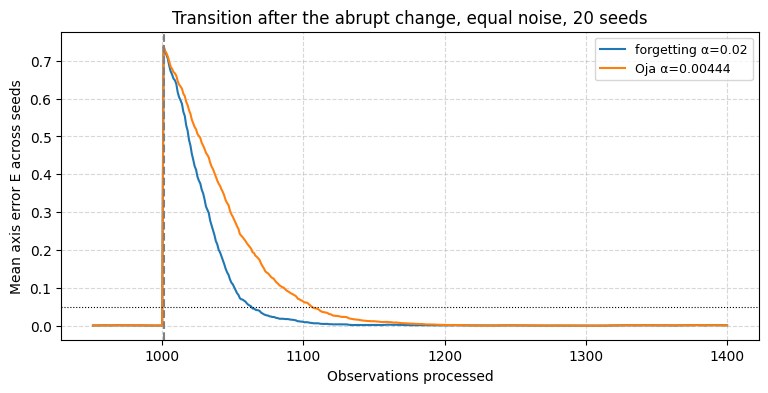

In [33]:
alpha, alpha_oja = gains[1], oja_gains[1]
fig, ax = plt.subplots(figsize=(9, 4))
zoom = np.arange(switch_step - 50, switch_step + 400)
for key, a, name in [('forgetting', alpha, f'forgetting α={alpha:g}'), ('oja', alpha_oja, f'Oja α={alpha_oja:.5f}')]:
    ax.plot(zoom + 1, results[key, 'abrupt'][a][0].mean(axis=0)[zoom], label=name)
ax.axvline(switch_step + 1, color='gray', linestyle='--')
ax.axhline(recovery_threshold, color='black', linestyle=':', linewidth=0.8)
ax.set_xlabel('Observations processed')
ax.set_ylabel('Mean axis error E across seeds')
ax.set_title('Transition after the abrupt change, equal noise, 20 seeds')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(fontsize=9)
plt.show()

### Results

- **Equal noise holds.** The stationary errors are $0.0072$ against $0.0068$, $0.00123$ against $0.00121$, and $0.00027$ against $0.00030$. The small excess for the largest gain is the separation at large gains seen in Section 2. For the smallest gain, see the note below.
- **Smooth rotation: the same lag.** For $\alpha=0.02$ the mean signed angle is $-2.91^\circ$ (forgetting) and $-2.93^\circ$ (Oja), for $\alpha=0.1$ $-0.65^\circ$ and $-0.64^\circ$. For the smallest gain Oja lags more ($-11.3^\circ$ against $-10.1^\circ$) and has a higher error ($0.039$ against $0.031$).
- **Random drift:** equal for $\alpha=0.02$ ($0.00366$ and $0.00368$); forgetting is slightly better for the other two gains.
- **Abrupt change: forgetting recovers faster at every gain.** Post-change error $0.0110$ against $0.0144$, $0.0234$ against $0.0358$, $0.0894$ against $0.1383$; median delay $53.5$ against $58.5$, $91.5$ against $130$, $260.5$ against $423$. With the smallest gain, Oja has not fully recovered even in the last 500 steps ($0.0040$ against $0.0007$).

At equal noise, Oja and forgetting PCA behave the same near the true direction: same noise, same lag, same tracking of slow changes. They differ after a large change, where forgetting PCA is faster.

**Note on the initial direction.** In every stream the true axis starts at $\theta_0=0$, and `oja_pca` starts from the direction $(1,0)$, which is exactly the true axis (the true axis: `theta0` in the settings cell and `data_generators.py`; the initial direction: `oja_pca` in `methods.py`). With a large gain this makes no difference, because the start-up lasts only a few steps. With a small gain Oja moves slowly, so for a long time its error reflects the lucky starting point rather than its own convergence.

The next cell repeats the stationary runs with the true axis starting at $1$ radian instead of $0$ (20 seeds; the initial direction is still $(1,0)$). For the smallest Oja gain the error after warm-up rises from $0.00027$ to $0.018$; for the two larger gains it hardly changes ($0.0072$ in both cases, $0.00123$ against $0.00127$).

Forgetting PCA and the windows are not affected, because they do not keep a starting direction: their estimate is determined by the data from the first observations. TW-API does start from the direction $(1,0)$, like Oja, but it is not affected after the warm-up: at the start the energy of its window is small, so its effective gain is large and it aligns with the data within a few tens of steps (with the true axis at $1$ rad instead of $0$, its error in the first $200$ steps roughly doubles, from about $0.005$ to $0.009$ for $w=99$ and $w=399$, while the error after warm-up is unchanged). For the two larger gains the conclusions of this notebook are unchanged. For the smallest gain ($0.00111$), the stationary and pre-change errors of Oja, and the equal-noise agreement with forgetting PCA at that gain, are favoured by the starting point. The comparison after the abrupt change is not favoured, because there the direction has to move away from the old axis anyway.

In [34]:
# Stationary data with the true axis starting at 0 (as in the rest of the notebook) or at 1 rad;
# every method keeps its usual start (Oja and TW-API from the direction (1, 0))
start_axes = [0.0, 1.0]
check_streams = {t0: [generate_stationary(run_seed, n_samples=n_samples, lam1=lam1, lam2=lam2, theta0=t0)
                      for run_seed in seeds] for t0 in start_axes}

def mean_error(fn, t0, period):
    # mean axis error over `period`, averaged over the 20 seeds
    return np.mean([axis_error(fn(X_run)[0], truth_run)[period].mean() for X_run, _, truth_run in check_streams[t0]])

after_warmup, first_steps = slice(warmup, None), slice(0, warmup)
rows = []
for alpha, alpha_oja in zip(gains, oja_gains):
    rows.append([f'Oja α={alpha_oja:.5f}', 'after warm-up']
                + [f'{mean_error(lambda X: oja_pca(X, alpha_oja), t0, after_warmup):.5f}' for t0 in start_axes])
    rows.append([f'forgetting α={alpha:g}', 'after warm-up']
                + [f'{mean_error(lambda X: forgetting_pca(X, alpha), t0, after_warmup):.5f}' for t0 in start_axes])
for w in [19, 99, 399]:
    for period_name, period in [(f'first {warmup} steps', first_steps), ('after warm-up', after_warmup)]:
        rows.append([f'TW-API w={w}', period_name]
                    + [f'{mean_error(lambda X: tw_api_pca(X, w), t0, period):.5f}' for t0 in start_axes])
ut.show_table(['Method', 'Period', 'True axis at 0 (as here)', 'True axis at 1 rad'], rows)

| Method | Period | True axis at 0 (as here) | True axis at 1 rad |
| --- | --- | --- | --- |
| Oja α=0.00111 | after warm-up | 0.00027 | 0.01788 |
| forgetting α=0.005 | after warm-up | 0.00030 | 0.00030 |
| Oja α=0.00444 | after warm-up | 0.00123 | 0.00127 |
| forgetting α=0.02 | after warm-up | 0.00121 | 0.00121 |
| Oja α=0.02222 | after warm-up | 0.00718 | 0.00718 |
| forgetting α=0.1 | after warm-up | 0.00680 | 0.00680 |
| TW-API w=19 | first 200 steps | 0.00861 | 0.01337 |
| TW-API w=19 | after warm-up | 0.00619 | 0.00633 |
| TW-API w=99 | first 200 steps | 0.00478 | 0.00919 |
| TW-API w=99 | after warm-up | 0.00109 | 0.00110 |
| TW-API w=399 | first 200 steps | 0.00473 | 0.00912 |
| TW-API w=399 | after warm-up | 0.00025 | 0.00025 |


# Summary

- **Oja PCA** updates the leading direction directly with the normalized rule of the proposal (eq. 2–3), with a fixed gain or a gain sequence.
- **Comparable gains.** The gain does not play the same role in the two updates: Oja's step grows with the variance of the data. With the gain scaled as $\alpha_{\text{Oja}}=\alpha/(\lambda_1-\lambda_2)$, Oja has the same stationary error as forgetting PCA with $\alpha$ (within $7\%$ for $\alpha$ from $0.002$ to $0.4$, Section 2) and the same lag in smooth rotation (Section 3).
- **After a large abrupt change forgetting PCA recovers faster** at every gain (Section 3).


# Sources

The sources are cited where they are used: Oja's update in Section 1, the scale of the Oja gains in Section 2. The rule $\alpha_{\text{Oja}}=\alpha/(\lambda_1-\lambda_2)$ is our choice, checked numerically in Section 2 but motivated by the following sources. See `docs/literature_review.md`, Section 5 (Oja's method) and Section 6 (comparing methods at equal memory).

- T. W. Anderson (1963). Asymptotic theory for principal component analysis. *Annals of Mathematical Statistics* (eq. 2.27: asymptotic covariance of the sample eigenvectors, used in Section 2).
- E. Oja (1982). Simplified neuron model as a principal component analyzer. *Journal of Mathematical Biology*
- E. Oja, J. Karhunen (1985). On stochastic approximation of the eigenvectors and eigenvalues of the expectation of a random matrix. *Journal of Mathematical Analysis and Applications* (Lemma 2, eqs. 12–13: mean dynamics of the update).
- C. J. Li, M. Wang, H. Liu, T. Zhang (2018). Near-optimal stochastic approximation for online principal component estimation. *Mathematical Programming* (Theorem 1, eq. 2.7: upper bound on the error with a constant step, constant not specified).
- H. Cardot, D. Degras (2018). Online principal component analysis in high dimension: which algorithm to choose? *International Statistical Review* (survey; reference [2] of the thesis proposal).


## Basic checks

The full set of tests is in `tests/test_pca.py`. These short checks repeat the main ones on the notebook data.

In [35]:
test_X = streams['stationary'][seed][0][:100]

# Eq. (2)-(3) of the proposal written with matrices, and eq. (4) for the innovation.
q_ref = np.array([1.0, 0.0])
q_oja, r_oja = oja_pca(test_X, 0.05)
for n, x in enumerate(test_X):
    P = np.eye(2) - np.outer(q_ref, q_ref)
    np.testing.assert_allclose(r_oja[n], np.linalg.norm(P @ x) ** 2, atol=1e-12)
    q_tilde = q_ref + 0.05 * P @ np.outer(x, x) @ q_ref
    q_ref = q_tilde / np.linalg.norm(q_tilde)
    np.testing.assert_allclose(q_oja[n], q_ref, atol=1e-12)

# Unit directions and causality.
np.testing.assert_allclose(np.linalg.norm(q_oja, axis=1), 1, atol=1e-12)
np.testing.assert_allclose(oja_pca(test_X[:40], 0.05)[0], q_oja[:40], atol=1e-12)

# A constant gain sequence gives the same result as the scalar gain.
np.testing.assert_array_equal(oja_pca(test_X, np.full(len(test_X), 0.05))[0], q_oja)

# Oja gains of Part 1: the forgetting gains divided by the spectral gap (Section 2).
np.testing.assert_allclose(np.array(oja_gains) * spectral_gap, gains)
print('All checks passed.')

All checks passed.
